In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy import signal
import os
from scipy.ndimage import gaussian_filter
from scipy.signal import wiener

Cortesia de Thomas Andrade


In [2]:
def matrixCreator(raw, pixelsX, pixelsY):
    matrix = []
    for i in range(0, len(raw), pixelsX*pixelsY):
        blank = np.zeros((pixelsX, pixelsY))
        for j in range(0, pixelsX):
            for k in range(0, pixelsY):
                blank[j, k] = raw[k + pixelsX*j + i]
        matrix.append(blank) 
    return matrix

def dataCreator(filename, pixelsX, pixelsY):
    raw_array = np.fromfile(filename, dtype = "float32")
    matrix = matrixCreator(raw_array, pixelsX, pixelsY)
    return matrix

def imageCreator(data, COLValue):
    image = []
    mean = 0
    for i in range(0, COLValue + 1):
        mean += data[i]
    mean = mean/(COLValue + 1)
    image.append(mean)  
    return image[0]

In [3]:

COL = 0 # Cambiar por el tipo de adquisición.
pixelsX = 256 
pixelsY = 256

In [4]:
#Metodo de Carga
#sample = dataCreator(directorio, pixelsX, pixelsY)
#image = imageCreator(sample, COL)
#plt.imshow(image, cmap='gray')

Funciones de graficar

In [5]:

def graficar_tn_df_sn(attenuation, differential_phase_contrast, dark_field):
    """
    Grafica las 3 imágenes resultantes ajustando la relación de aspecto 
    para que se visualicen de forma cuadrada a pesar de la compresión de 1/3.
    """
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    imagenes = [
        (attenuation, "Attenuation (Tn)", "gray"),
        (differential_phase_contrast, "Differential Phase Contrast (Dn)", "coolwarm"),
        (dark_field, "Dark Field (Sn)", "plasma")
    ]
    
    for ax, (img, titulo, cmap) in zip(axes, imagenes):
        # 'aspect="auto"' o ajustar losextent permite estirar la imagen comprimida horizontalmente
        im = ax.imshow(img, cmap=cmap, aspect='auto')
        ax.set_title(titulo)
        ax.axis('on')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        
    plt.tight_layout()
    plt.show()

def graficar_tn_dfodpc(attenuation, dark_field):
    """
    Grafica las 2 imágenes resultantes ajustando la relación de aspecto 
    para que se visualicen de forma cuadrada a pesar de la compresión de 1/2.
    """
    fig, axes = plt.subplots(1, 2, figsize=(10, 5))
    
    imagenes = [
        (attenuation, "Attenuation (Tn)", "gray"),
        (dark_field, "Dark Field (Sn)", "plasma")
    ]
    
    for ax, (img, titulo, cmap) in zip(axes, imagenes):
        # 'aspect="auto"' o ajustar losextent permite estirar la imagen comprimida horizontalmente
        im = ax.imshow(img, cmap=cmap, aspect='auto')
        ax.set_title(titulo)
        ax.axis('on')
        fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
        
    plt.tight_layout()
    plt.show()

def comparar_filtros_2x2(attenuation, dark_field):
    """
    Recibe las 2 imágenes del algoritmo de grating y genera una cuadrícula 2x2:
    - Fila 0: Filtro Pasabajas (Gaussian)
    - Fila 1: Filtro Wiener
    - Columna 0: Attenuation
    - Columna 1: Dark Field
    
    Corrige automáticamente la compresión horizontal de 1/3 mediante 'extent' 
    para que las imágenes se visualicen con las dimensiones correctas (proporción cuadrada).
    """
    # Convertir a arrays de numpy por seguridad
    att = np.array(attenuation, dtype=float)
    
    df = np.array(dark_field, dtype=float)
    
    # 1. Aplicar Filtro Pasabajas (Gaussiano)
    att_pb = gaussian_filter(att, sigma=1.5)

    df_pb  = gaussian_filter(df, sigma=1.5)
    
    # 2. Aplicar Filtro Wiener
    att_w = wiener(att, mysize=3)

    df_w  = wiener(df, mysize=3)
    
    # Configurar la figura: 2 filas (filtros) x 2 columnas (tipos de imagen)
    fig, axes = plt.subplots(2, 2, figsize=(15, 9))
    
#
    # --- Fila 0: Filtro Pasabajas ---
    im00 = axes[0, 0].imshow(att_pb, cmap='gray',  aspect='auto')
    axes[0, 0].set_title("Attenuation (Pasabajas)")
    fig.colorbar(im00, ax=axes[0, 0], fraction=0.046, pad=0.04)
    
    im01 = axes[0, 1].imshow(df_pb, cmap='plasma',  aspect='auto')
    axes[0, 1].set_title("Dark Field (Pasabajas)")
    fig.colorbar(im01, ax=axes[0, 1], fraction=0.046, pad=0.04)
    
    # --- Fila 1: Filtro Wiener ---
    im10 = axes[1, 0].imshow(att_w, cmap='gray',  aspect='auto')
    axes[1, 0].set_title("Attenuation (Wiener)")
    fig.colorbar(im10, ax=axes[1, 0], fraction=0.046, pad=0.04)
    
    im11 = axes[1, 1].imshow(df_w, cmap='plasma', aspect='auto')
    axes[1, 1].set_title("Dark Field (Wiener)")
    fig.colorbar(im11, ax=axes[1, 1], fraction=0.046, pad=0.04)
    
    # Etiquetas de los ejes para evidenciar la corrección de escala
    for fila in axes:
        for ax in fila:
            ax.set_xlabel("Eje X (píxeles expandidos)")
            ax.set_ylabel("Eje Y (píxeles)")
            
    plt.tight_layout()
    plt.show()

def comparar_filtros_2x3(attenuation, dpc, dark_field):
    """
    Recibe las 3 imágenes del algoritmo de grating y genera una cuadrícula 2x3:
    - Fila 0: Filtro Pasabajas (Gaussian)
    - Fila 1: Filtro Wiener
    - Columna 0: Attenuation
    - Columna 1: Differential Phase Contrast (DPC)
    - Columna 2: Dark Field
    
    Corrige automáticamente la compresión horizontal de 1/3 mediante 'extent' 
    para que las imágenes se visualicen con las dimensiones correctas (proporción cuadrada).
    """
    # Convertir a arrays de numpy por seguridad
    att = np.array(attenuation, dtype=float)
    dpc_img = np.array(dpc, dtype=float)
    df = np.array(dark_field, dtype=float)
    
    # 1. Aplicar Filtro Pasabajas (Gaussiano)
    att_pb = gaussian_filter(att, sigma=1.5)
    dpc_pb = gaussian_filter(dpc_img, sigma=1.5)
    df_pb  = gaussian_filter(df, sigma=1.5)
    
    # 2. Aplicar Filtro Wiener
    att_w = wiener(att, mysize=3)
    dpc_w = wiener(dpc_img, mysize=3)
    df_w  = wiener(df, mysize=3)
    
    # Configurar la figura: 2 filas (filtros) x 3 columnas (tipos de imagen)
    fig, axes = plt.subplots(2, 3, figsize=(15, 9))
    
   
    # --- Fila 0: Filtro Pasabajas ---
    im00 = axes[0, 0].imshow(att_pb, cmap='gray',  aspect='auto')
    axes[0, 0].set_title("Attenuation (Pasabajas)")
    fig.colorbar(im00, ax=axes[0, 0], fraction=0.046, pad=0.04)
    
    im01 = axes[0, 1].imshow(dpc_pb, cmap='coolwarm',  aspect='auto')
    axes[0, 1].set_title("DPC (Pasabajas)")
    fig.colorbar(im01, ax=axes[0, 1], fraction=0.046, pad=0.04)
    
    im02 = axes[0, 2].imshow(df_pb, cmap='plasma',  aspect='auto')
    axes[0, 2].set_title("Dark Field (Pasabajas)")
    fig.colorbar(im02, ax=axes[0, 2], fraction=0.046, pad=0.04)
    
    # --- Fila 1: Filtro Wiener ---
    im10 = axes[1, 0].imshow(att_w, cmap='gray',  aspect='auto')
    axes[1, 0].set_title("Attenuation (Wiener)")
    fig.colorbar(im10, ax=axes[1, 0], fraction=0.046, pad=0.04)
    
    im11 = axes[1, 1].imshow(dpc_w, cmap='coolwarm',  aspect='auto')
    axes[1, 1].set_title("DPC (Wiener)")
    fig.colorbar(im11, ax=axes[1, 1], fraction=0.046, pad=0.04)
    
    im12 = axes[1, 2].imshow(df_w, cmap='plasma', aspect='auto')
    axes[1, 2].set_title("Dark Field (Wiener)")
    fig.colorbar(im12, ax=axes[1, 2], fraction=0.046, pad=0.04)
    
    # Etiquetas de los ejes para evidenciar la corrección de escala
    for fila in axes:
        for ax in fila:
            ax.set_xlabel("Eje X (píxeles expandidos)")
            ax.set_ylabel("Eje Y (píxeles)")
            
    plt.tight_layout()
    plt.show()


___

Retrieval algoritm

<hr style="border: none; border-top: 2px dotted #808080; height: 0;">

A. Single-Mask DPC Configuration

Atenuation and DPC 

PARAMETERS:
Distance Source-Mask:60cm
Distance Mask-Detector:60cm
Focal Length:7um
Events:2000000000
Energy:30Kev


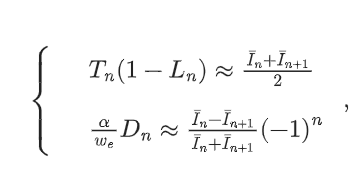 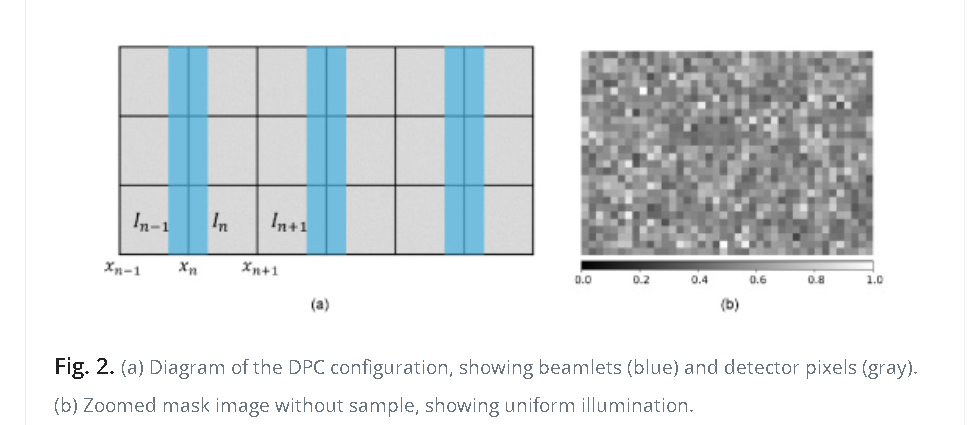

FLAT FIELD  DPC

CARGA Att y DPC

------------------------

Dark Field


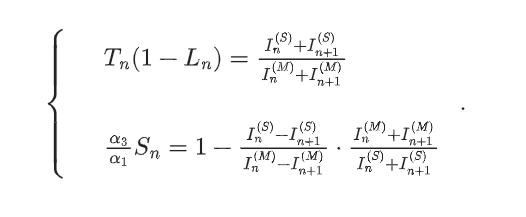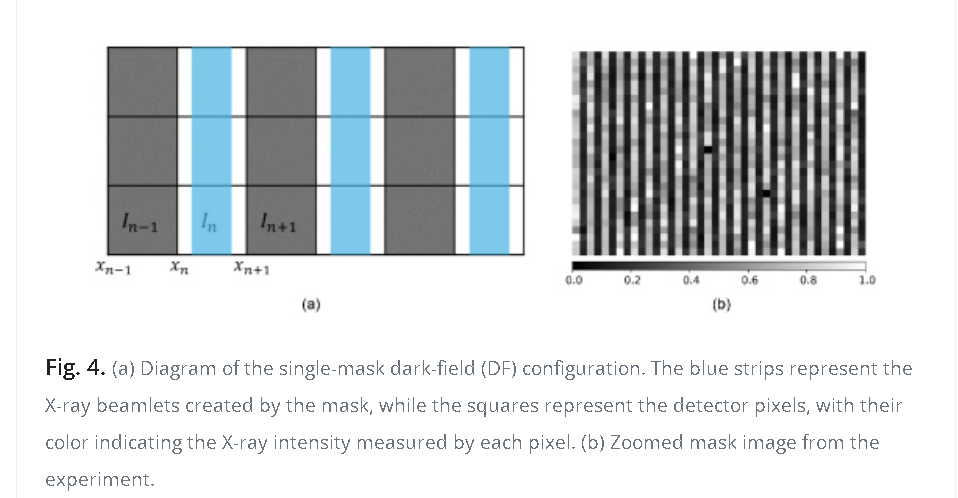

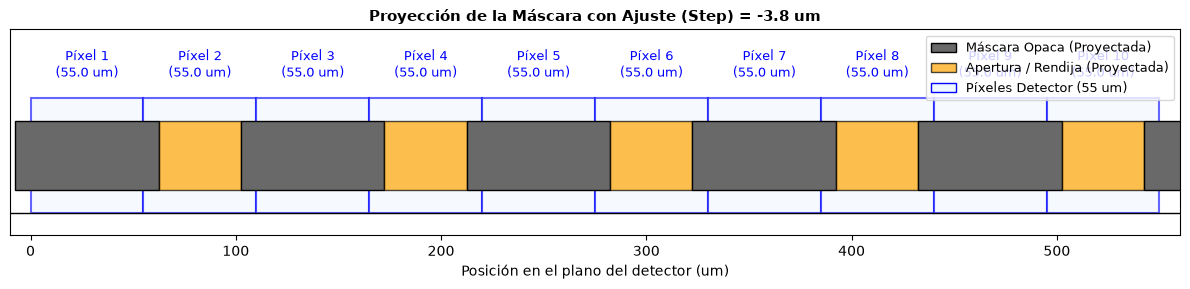

In [6]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
#PARAMETROS EXPERIMENTALES(MODIFICAR A CONVENIENCIA)
step = -3.8  # Desplazamiento inicial de la máscara en micras Caso M=x2: debe variar 0-27.5(un pixel)
mask_pitch= 55.0  # Pitch de la máscara en micras (55 um)
mask_aperture=20.0  # Apertura de la máscara en micras (20 um)
pixel_pitch = 55.0
# Configuración de la figura
fig, ax = plt.subplots(figsize=(12, 3))

# Parámetros geométricos (en um)
M=2.0  # Magnificación del sistema óptico
mask_pitch_proj = mask_pitch*M  # 55 um * M
mask_aperture_proj = mask_aperture*M # 20 um * M
mask_opaque_proj = mask_pitch_proj - mask_aperture_proj

# Parámetro de ajuste / desplazamiento (step) en micras
ajuste_step = step * M

# Dibujar píxeles del detector
num_pixels = 10
for i in range(num_pixels):
    rect_pixel = patches.Rectangle((i * pixel_pitch, 0), pixel_pitch, 1, 
                                   linewidth=1.5, edgecolor='blue', facecolor='aliceblue', alpha=0.6)
    ax.add_patch(rect_pixel)
    ax.text(i * pixel_pitch + pixel_pitch/2, 1.15, f'Píxel {i+1}\n({pixel_pitch} um)', 
            ha='center', va='bottom', fontsize=9, color='blue')

# Dibujar máscara proyectada (varios periodos) aplicando el ajuste inicial
current_pos = ajuste_step
while current_pos < num_pixels * pixel_pitch + mask_pitch_proj:
    # Parte opaca de la máscara
    rect_opaque = patches.Rectangle((current_pos, 0.2), mask_opaque_proj, 0.6, 
                                     linewidth=1, edgecolor='black', facecolor='dimgray')
    ax.add_patch(rect_opaque)
    
    # Apertura de la máscara
    rect_aperture = patches.Rectangle((current_pos + mask_opaque_proj, 0.2), mask_aperture_proj, 0.6, 
                                       linewidth=1, edgecolor='black', facecolor='orange', alpha=0.7)
    ax.add_patch(rect_aperture)
    
    current_pos += mask_pitch_proj

# Ajustes de los ejes
ax.set_xlim(-10, num_pixels * pixel_pitch + 10)
ax.set_ylim(-0.2, 1.6)
ax.axhline(0, color='black', linewidth=1)
ax.set_yticks([])
ax.set_xlabel('Posición en el plano del detector (um)', fontsize=10)
ax.set_title(f'Proyección de la Máscara con Ajuste (Step) = {ajuste_step/2} um', fontsize=11, weight='bold')

# Leyenda manual
from matplotlib.lines import Line2D
legend_elements = [
    patches.Patch(facecolor='dimgray', edgecolor='black', label='Máscara Opaca (Proyectada)'),
    patches.Patch(facecolor='orange', edgecolor='black', alpha=0.7, label='Apertura / Rendija (Proyectada)'),
    patches.Patch(facecolor='aliceblue', edgecolor='blue', label='Píxeles Detector (55 um)')
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

Flat Field DF


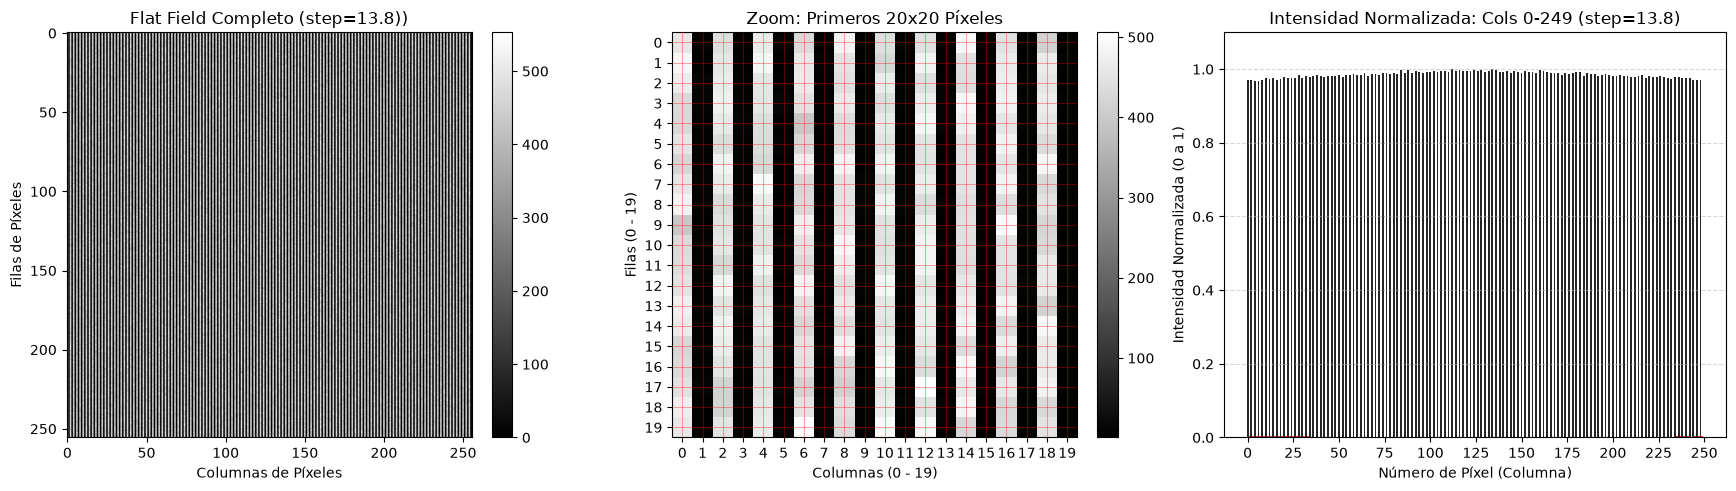

In [7]:

ff_df_dir=r"Resultados\DPC o DF/FF/resultados_barrido_DF/pos_13.8.raw"
sample = dataCreator(ff_df_dir, pixelsX, pixelsY)
flat_field_dfodpc = imageCreator(sample, COL)
 # Promedio por columna (filas, axis=0) de la imagen sin filtrar
column_means = np.mean(flat_field_dfodpc, axis=0)
    
 # Tomar las primeras 250 columnas
num_pixeles = 250
cols_250 = column_means[:num_pixeles]

    # Normalización Min-Max de las primeras 250 columnas
min_val, max_val = np.min(cols_250), np.max(cols_250)
norm_min_max = (cols_250 - min_val) / (max_val - min_val) if max_val > min_val else cols_250

    # --- PATRÓN DE COLORES 3 COLUMNAS (Negro, Negro, Rojo) ---
 # --- DEFINIR COLORES ALTERNADOS (PARES: NEGRO, IMPARES: ROJO) ---
colores_barras = ['black' if idx % 2 == 0 else 'red' for idx in range(num_pixeles)]

    # --- GRAFICADO ---
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

    # Panel 1: Imagen Completa Original
im1 = ax1.imshow(flat_field_dfodpc, cmap='gray')
ax1.set_title(f"Flat Field Completo (step=13.8))")
ax1.set_xlabel("Columnas de Píxeles")
ax1.set_ylabel("Filas de Píxeles")
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

    # Panel 2: Zoom 20x20
zoom_region = flat_field_dfodpc[:20, :20]
im2 = ax2.imshow(zoom_region, cmap='gray', interpolation='nearest')
ax2.set_title("Zoom: Primeros 20x20 Píxeles")
ax2.set_xlabel("Columnas (0 - 19)")
ax2.set_ylabel("Filas (0 - 19)")
ax2.set_xticks(np.arange(20))
ax2.set_yticks(np.arange(20))
ax2.grid(True, which='both', color='red', linestyle='-', linewidth=0.5, alpha=0.5)
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

    # Panel 3: Histograma Normalizado (Patrón 2 Negro - 1 Rojo)
ax3.bar(np.arange(num_pixeles), norm_min_max, width=1.0, color=colores_barras, alpha=0.85)
    
ax3.set_title(f"Intensidad Normalizada: Cols 0-{num_pixeles-1} (step=13.8)")
ax3.set_xlabel("Número de Píxel (Columna)")
ax3.set_ylabel("Intensidad Normalizada (0 a 1)")
    
    # Ajustar marcas para 250 elementos (marcas cada 25 píxeles)
ax3.set_xticks(np.arange(0, num_pixeles + 1, 25))
ax3.set_ylim(0, 1.1)
ax3.grid(True, linestyle='--', alpha=0.5, axis='y')

plt.tight_layout()
plt.show()



Iteracion para el encuadre (ctrl+k ctrl+c comentar | ctrl+k ctrl+U descomentar)

In [8]:
# inicio = 0.0
# fin = 18.4
# paso = 0.2

# for i in np.arange(inicio, fin, paso):
#     pos_val = float(i)
#     ff_df_dir = os.path.join("Resultados/DPC o DF/FF/resultados_barrido_DF", f"pos_{pos_val:.1f}.raw")
    
#     if not os.path.exists(ff_df_dir):
#         continue

#     sample = dataCreator(ff_df_dir, pixelsX, pixelsY)
#     ff_image = imageCreator(sample, COL)

#     # 1. Promedio por columna (filas, axis=0)
#     column_means = np.mean(ff_image, axis=0)
    
#     # Tomar las primeras 250 columnas
#     num_pixeles = 250
#     cols_250 = column_means[:num_pixeles]

#     # --- NORMALIZACIÓN MIN-MAX ---
#     min_val, max_val = np.min(cols_250), np.max(cols_250)
#     norm_min_max = (cols_250 - min_val) / (max_val - min_val) if max_val > min_val else cols_250

#     # --- DEFINIR COLORES ALTERNADOS (PARES: NEGRO, IMPARES: ROJO) ---
#     colores_barras = ['black' if idx % 2 == 0 else 'red' for idx in range(num_pixeles)]

#     # 2. Configurar la figura con 3 paneles
#     fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

#     # Panel 1: Completo
#     im1 = ax1.imshow(ff_image, cmap='gray')
#     ax1.set_title(f"Flat Field Completo (pos_{pos_val:.1f})")
#     ax1.set_xlabel("Columnas de Píxeles")
#     ax1.set_ylabel("Filas de Píxeles")
#     fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

#     # Panel 2: Zoom 20x20
#     zoom_region = ff_image[:20, :20]
#     im2 = ax2.imshow(zoom_region, cmap='gray', interpolation='nearest')
#     ax2.set_title("Zoom: Primeros 20x20 Píxeles")
#     ax2.set_xlabel("Columnas (0 - 19)")
#     ax2.set_ylabel("Filas (0 - 19)")
#     ax2.set_xticks(np.arange(20))
#     ax2.set_yticks(np.arange(20))
#     ax2.grid(True, which='both', color='red', linestyle='-', linewidth=0.5, alpha=0.5)
#     fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

#     # Panel 3: Histograma Normalizado (Pares: Negro, Impares: Rojo)
#     ax3.bar(np.arange(num_pixeles), norm_min_max, width=1.0, color=colores_barras, alpha=0.85)
    
#     ax3.set_title(f"Intensidad Normalizada: Cols 0-{num_pixeles-1} (pos_{pos_val:.1f})")
#     ax3.set_xlabel("Número de Píxel (Columna)")
#     ax3.set_ylabel("Intensidad Normalizada (0 a 1)")
    
#     # Marcas cada 25 píxeles para mantener legible el eje X con 250 elementos
#     ax3.set_xticks(np.arange(0, num_pixeles + 1, 25))
#     ax3.set_ylim(0, 1.1)
#     ax3.grid(True, linestyle='--', alpha=0.5, axis='y')

#     plt.tight_layout()
#     plt.show()

----------------------

Muestra

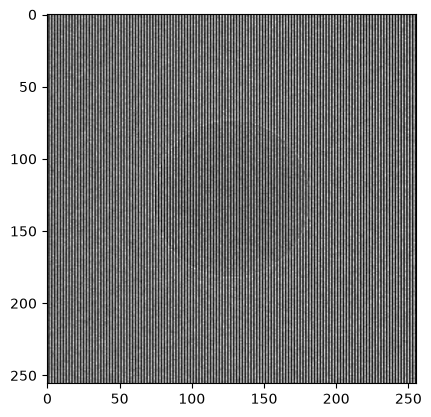

In [9]:
#carga Sample
sample_dfodpc_dir=r"Resultados\DPC o DF\Sample\dfodpc_esfera_1000um.raw"
sample = dataCreator(sample_dfodpc_dir, pixelsX, pixelsY)
sample_dfodpc = imageCreator(sample, COL)
plt.imshow(sample_dfodpc, cmap='gray')

Algoritmo

In [10]:
def recuperar_imagenes_dfodpc2(flat_field, sample):
    """
    Calcula las imágenes de atenuación (att) y campo obscuro (dark_field)
    a partir de flat_field (I^S) y sample (I^M), reduciendo el ancho a la mitad
    utilizando pares de píxeles (n, n+1).
    """
    IS = np.array(flat_field, dtype=float)
    IM = np.array(sample, dtype=float)
    
    eps = 1e-10
    filas, columnas = IS.shape
    
    # El ancho se reduce a la mitad (paso de 2 en 2)
    nuevo_ancho = columnas // 2
    
    att = np.zeros((filas, nuevo_ancho))
    dark_field = np.zeros((filas, nuevo_ancho))
    
    for j in range(nuevo_ancho):
        # Índices para el par de píxeles (n, n+1)
        idx_n = 2 * j
        idx_n_plus_1 = 2 * j + 1
        
        if idx_n_plus_1 >= columnas:
            break
            
        # Extraer valores para flat_field (I^S) y sample (I^M)
        Is_0  = IS[:, idx_n]
        Is_p1 = IS[:, idx_n_plus_1]
        
        Im_0  = IM[:, idx_n]
        Im_p1 = IM[:, idx_n_plus_1]
        
        # Sumas de los pares
        suma_Is = Is_0 + Is_p1
        suma_Im = Im_0 + Im_p1
        
        # 1. Atenuación (att / Tn) -> Relación de sumas de intensidades
        att[:, j] = suma_Is / (suma_Im + eps)
        
        # 2. Dark Field (Sn) -> Basado en la ecuación inferior de la imagen
        numerador_diff = Is_0 - Is_p1
        denominador_diff = Im_0 - Im_p1
        
        ratio_diff = numerador_diff / (denominador_diff + eps)
        ratio_suma = suma_Im / (suma_Is + eps)
        
        dark_field[:, j] = 1.0 - (ratio_diff * ratio_suma)
        
    return att, dark_field

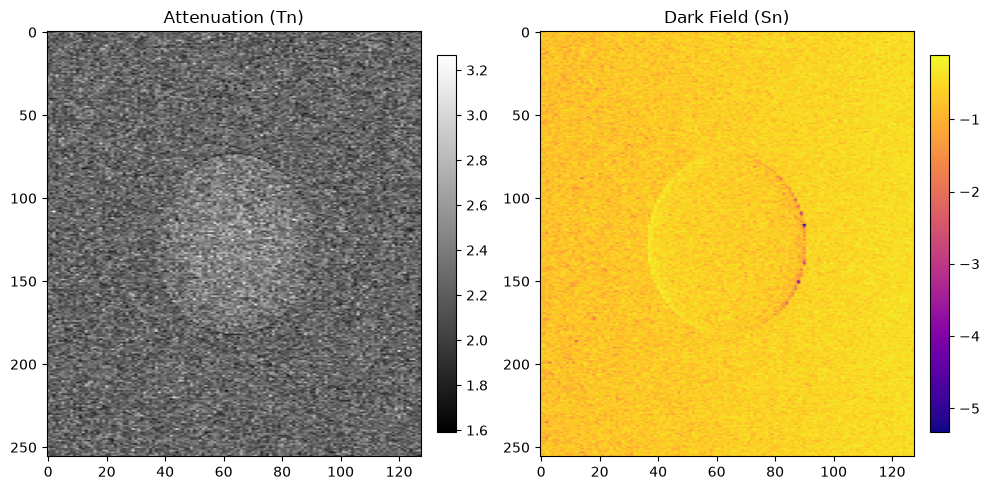

In [24]:
att, dark_field = recuperar_imagenes_dfodpc2(flat_field_dfodpc, sample_dfodpc)
graficar_tn_dfodpc(att, dark_field)

filtros

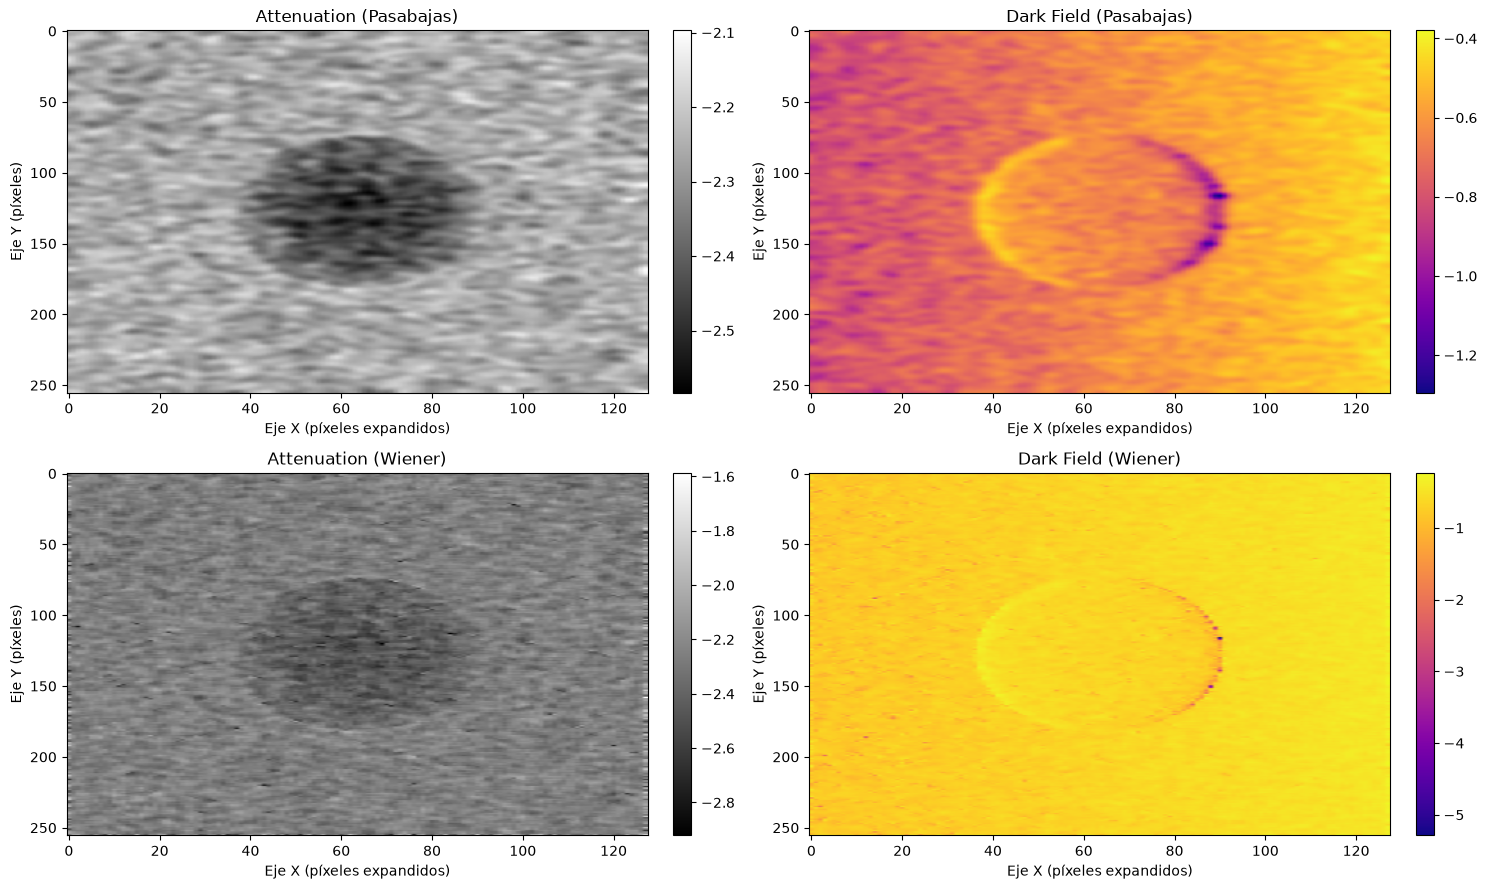

In [12]:
comparar_filtros_2x2(-att, dark_field)

<hr style="border: none; border-top: 2px dotted #808080; height: 0;">

B. Single-Mask DF-DPC Configuration

PARAMETERS:
Distance Source-Mask:60cm
Distance Mask-Detector:120cm
Focal Length:7um
Events:2000000000
Energy:10-30Kev


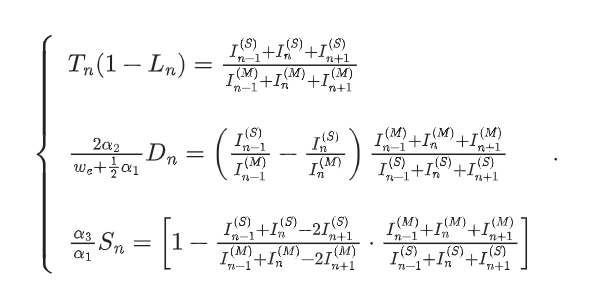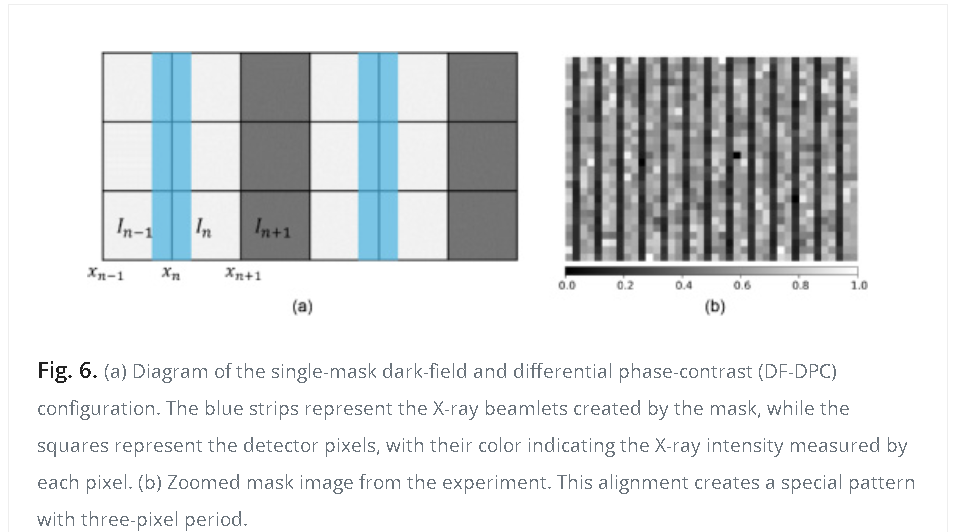

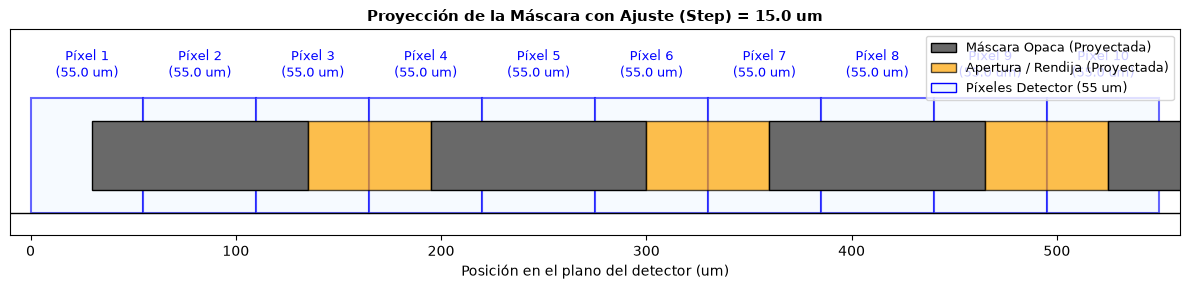

In [13]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches
#PARAMETROS EXPERIMENTALES(MODIFICAR A CONVENIENCIA)
step = 10  # Desplazamiento inicial de la máscara en micras Caso M=x3: debe variar 0-18.3(un pixel)
mask_pitch= 55.0  # Pitch de la máscara en micras (55 um)
mask_aperture=20.0  # Apertura de la máscara en micras (20 um)
pixel_pitch = 55.0
# Configuración de la figura
fig, ax = plt.subplots(figsize=(12, 3))

# Parámetros geométricos (en um)
M=3.0  # Magnificación del sistema óptico
mask_pitch_proj = mask_pitch*M  # 55 um * M
mask_aperture_proj = mask_aperture*M # 20 um * M
mask_opaque_proj = mask_pitch_proj - mask_aperture_proj

# Parámetro de ajuste / desplazamiento (step) en micras
ajuste_step = step * M

# Dibujar píxeles del detector
num_pixels = 10
for i in range(num_pixels):
    rect_pixel = patches.Rectangle((i * pixel_pitch, 0), pixel_pitch, 1, 
                                   linewidth=1.5, edgecolor='blue', facecolor='aliceblue', alpha=0.6)
    ax.add_patch(rect_pixel)
    ax.text(i * pixel_pitch + pixel_pitch/2, 1.15, f'Píxel {i+1}\n({pixel_pitch} um)', 
            ha='center', va='bottom', fontsize=9, color='blue')

# Dibujar máscara proyectada (varios periodos) aplicando el ajuste inicial
current_pos = ajuste_step
while current_pos < num_pixels * pixel_pitch + mask_pitch_proj:
    # Parte opaca de la máscara
    rect_opaque = patches.Rectangle((current_pos, 0.2), mask_opaque_proj, 0.6, 
                                     linewidth=1, edgecolor='black', facecolor='dimgray')
    ax.add_patch(rect_opaque)
    
    # Apertura de la máscara
    rect_aperture = patches.Rectangle((current_pos + mask_opaque_proj, 0.2), mask_aperture_proj, 0.6, 
                                       linewidth=1, edgecolor='black', facecolor='orange', alpha=0.7)
    ax.add_patch(rect_aperture)
    
    current_pos += mask_pitch_proj

# Ajustes de los ejes
ax.set_xlim(-10, num_pixels * pixel_pitch + 10)
ax.set_ylim(-0.2, 1.6)
ax.axhline(0, color='black', linewidth=1)
ax.set_yticks([])
ax.set_xlabel('Posición en el plano del detector (um)', fontsize=10)
ax.set_title(f'Proyección de la Máscara con Ajuste (Step) = {ajuste_step/2} um', fontsize=11, weight='bold')

# Leyenda manual
from matplotlib.lines import Line2D
legend_elements = [
    patches.Patch(facecolor='dimgray', edgecolor='black', label='Máscara Opaca (Proyectada)'),
    patches.Patch(facecolor='orange', edgecolor='black', alpha=0.7, label='Apertura / Rendija (Proyectada)'),
    patches.Patch(facecolor='aliceblue', edgecolor='blue', label='Píxeles Detector (55 um)')
]
ax.legend(handles=legend_elements, loc='upper right', fontsize=9)

plt.tight_layout()
plt.show()

Flat Field (UNICO)



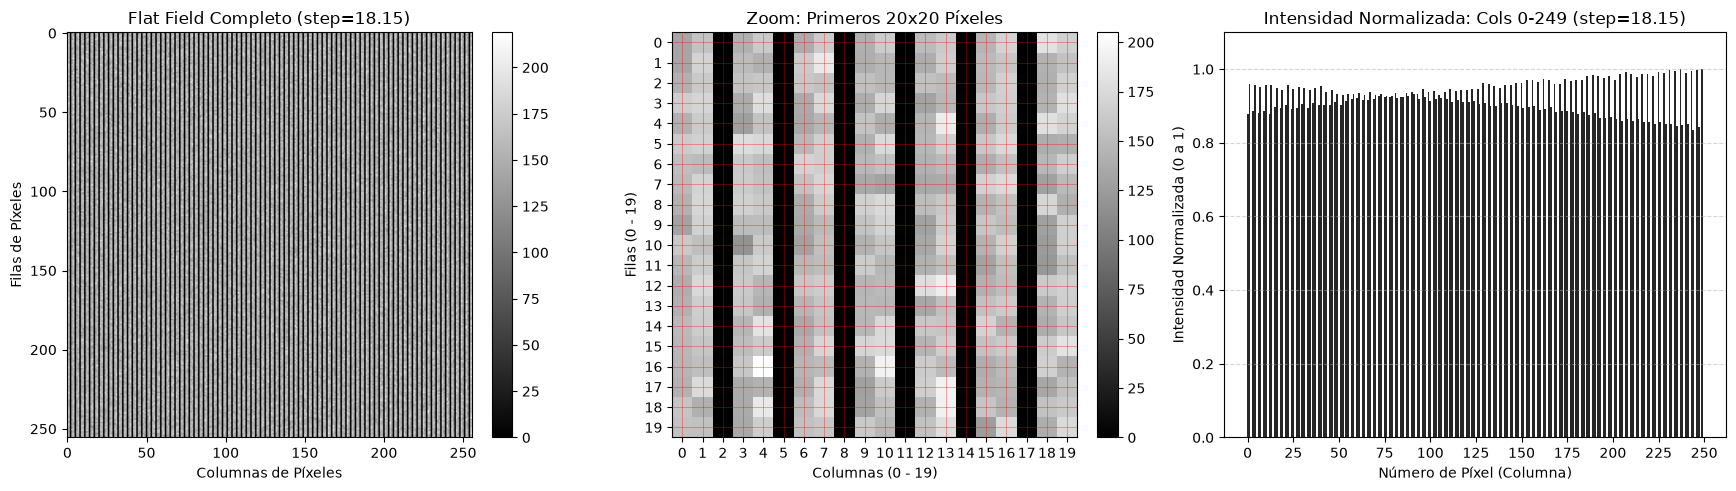

In [14]:


ff_df_dir=r"Resultados/DPCyDF/FF/resultados_barrido_dfydpc/pos_18.15.raw"
sample = dataCreator(ff_df_dir, pixelsX, pixelsY)
flat_field_dfydpc = imageCreator(sample, COL)
 # Promedio por columna (filas, axis=0) de la imagen sin filtrar
column_means = np.mean(flat_field_dfydpc, axis=0)
    
 # Tomar las primeras 250 columnas
num_pixeles = 250
cols_250 = column_means[:num_pixeles]

    # Normalización Min-Max de las primeras 250 columnas
min_val, max_val = np.min(cols_250), np.max(cols_250)
norm_min_max = (cols_250 - min_val) / (max_val - min_val) if max_val > min_val else cols_250

    # --- PATRÓN DE COLORES 3 COLUMNAS (Negro, Negro, Rojo) ---
    # idx % 3 da 0 -> 1ª columna (negro)
    # idx % 3 da 1 -> 2ª columna (negro)
    # idx % 3 da 2 -> 3ª columna (rojo)
colores_barras = ['red' if idx % 3 == 2 else 'black' for idx in range(num_pixeles)]

    # --- GRAFICADO ---
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

    # Panel 1: Imagen Completa Original
im1 = ax1.imshow(flat_field_dfydpc, cmap='gray')
ax1.set_title(f"Flat Field Completo (step=18.15)")
ax1.set_xlabel("Columnas de Píxeles")
ax1.set_ylabel("Filas de Píxeles")
fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

    # Panel 2: Zoom 20x20
zoom_region = flat_field_dfydpc[:20, :20]
im2 = ax2.imshow(zoom_region, cmap='gray', interpolation='nearest')
ax2.set_title("Zoom: Primeros 20x20 Píxeles")
ax2.set_xlabel("Columnas (0 - 19)")
ax2.set_ylabel("Filas (0 - 19)")
ax2.set_xticks(np.arange(20))
ax2.set_yticks(np.arange(20))
ax2.grid(True, which='both', color='red', linestyle='-', linewidth=0.5, alpha=0.5)
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

    # Panel 3: Histograma Normalizado (Patrón 2 Negro - 1 Rojo)
ax3.bar(np.arange(num_pixeles), norm_min_max, width=1.0, color=colores_barras, alpha=0.85)
    
ax3.set_title(f"Intensidad Normalizada: Cols 0-{num_pixeles-1} (step=18.15)")
ax3.set_xlabel("Número de Píxel (Columna)")
ax3.set_ylabel("Intensidad Normalizada (0 a 1)")
    
    # Ajustar marcas para 250 elementos (marcas cada 25 píxeles)
ax3.set_xticks(np.arange(0, num_pixeles + 1, 25))
ax3.set_ylim(0, 1.1)
ax3.grid(True, linestyle='--', alpha=0.5, axis='y')

plt.tight_layout()
plt.show()
flat_field_DFyDPC=flat_field_dfydpc


Iteracion para el encuadre (ctrl+k ctrl+c comentar | ctrl+k ctrl+U descomentar)

In [15]:
# import glob
# import re

# # Directorio objetivo
# carpeta_datos = "Resultados/DPCyDF/FF/resultados_barrido_dfydpc"

# # 1. Buscar todos los archivos .raw en la carpeta
# patron_busqueda = os.path.join(carpeta_datos, "pos_*.raw")
# archivos_raw = glob.glob(patron_busqueda)

# # Función para extraer el valor numérico de la posición desde el nombre del archivo
# def extraer_posicion(ruta_archivo):
#     nombre = os.path.basename(ruta_archivo)
#     coincidencia = re.search(r"pos_([\d.]+)\.raw", nombre)
#     return float(coincidencia.group(1)) if coincidencia else -1.0

# # 2. Ordenar los archivos numéricamente por su posición (ej. pos_0.0.raw, pos_0.33.raw, etc.)
# archivos_ordenados = sorted(archivos_raw, key=extraer_posicion)

# print(f"Se encontraron {len(archivos_ordenados)} archivos .raw para procesar.")

# # 3. Iterar ordenadamente sobre todos los archivos encontrados
# for ff_df_dir in archivos_ordenados:
#     pos_val = extraer_posicion(ff_df_dir)
    
#     # Cargar datos de la imagen original
#     sample = dataCreator(ff_df_dir, pixelsX, pixelsY)
#     ff_image = imageCreator(sample, COL)

#     # Promedio por columna (filas, axis=0) de la imagen sin filtrar
#     column_means = np.mean(ff_image, axis=0)
    
#     # Tomar las primeras 250 columnas
#     num_pixeles = 250
#     cols_250 = column_means[:num_pixeles]

#     # Normalización Min-Max de las primeras 250 columnas
#     min_val, max_val = np.min(cols_250), np.max(cols_250)
#     norm_min_max = (cols_250 - min_val) / (max_val - min_val) if max_val > min_val else cols_250

#     # --- PATRÓN DE COLORES 3 COLUMNAS (Negro, Negro, Rojo) ---
#     # idx % 3 da 0 -> 1ª columna (negro)
#     # idx % 3 da 1 -> 2ª columna (negro)
#     # idx % 3 da 2 -> 3ª columna (rojo)
#     colores_barras = ['red' if idx % 3 == 2 else 'black' for idx in range(num_pixeles)]

#     # --- GRAFICADO ---
#     fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

#     # Panel 1: Imagen Completa Original
#     im1 = ax1.imshow(ff_image, cmap='gray')
#     ax1.set_title(f"Flat Field Completo (pos_{pos_val:.2f})")
#     ax1.set_xlabel("Columnas de Píxeles")
#     ax1.set_ylabel("Filas de Píxeles")
#     fig.colorbar(im1, ax=ax1, fraction=0.046, pad=0.04)

#     # Panel 2: Zoom 20x20
#     zoom_region = ff_image[:20, :20]
#     im2 = ax2.imshow(zoom_region, cmap='gray', interpolation='nearest')
#     ax2.set_title("Zoom: Primeros 20x20 Píxeles")
#     ax2.set_xlabel("Columnas (0 - 19)")
#     ax2.set_ylabel("Filas (0 - 19)")
#     ax2.set_xticks(np.arange(20))
#     ax2.set_yticks(np.arange(20))
#     ax2.grid(True, which='both', color='red', linestyle='-', linewidth=0.5, alpha=0.5)
#     fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04)

#     # Panel 3: Histograma Normalizado (Patrón 2 Negro - 1 Rojo)
#     ax3.bar(np.arange(num_pixeles), norm_min_max, width=1.0, color=colores_barras, alpha=0.85)
    
#     ax3.set_title(f"Intensidad Normalizada: Cols 0-{num_pixeles-1} (pos_{pos_val:.2f})")
#     ax3.set_xlabel("Número de Píxel (Columna)")
#     ax3.set_ylabel("Intensidad Normalizada (0 a 1)")
    
#     # Ajustar marcas para 250 elementos (marcas cada 25 píxeles)
#     ax3.set_xticks(np.arange(0, num_pixeles + 1, 25))
#     ax3.set_ylim(0, 1.1)
#     ax3.grid(True, linestyle='--', alpha=0.5, axis='y')

#     plt.tight_layout()
#     plt.show()

Carga Sample


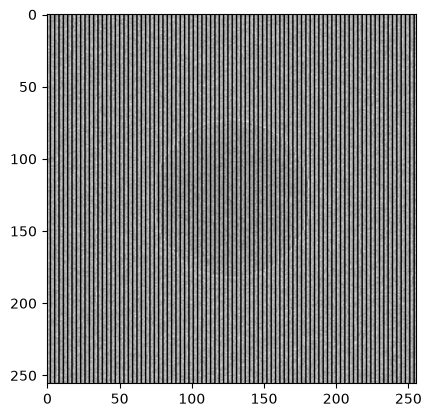

In [16]:
sample_dfydpc_dir=r"Resultados\DPCyDF\Sample\dfydpc_esfera_1000um"
sample = dataCreator(sample_dfydpc_dir, pixelsX, pixelsY)
sample_dfydpc = imageCreator(sample, COL)
plt.imshow(sample_dfydpc, cmap='gray')

-------------------------------------

Recuperacion imagenes


In [17]:
def calcular_imagenes_dfydpc(flat_field, sample):
    """
    Calcula las imágenes de atenuación, contraste de fase y campo obscuro 
    a partir de las matrices flat_field (I^S) y sample (I^M).
    Reduce la dimensión horizontal (eje X) agrupando de 3 en 3 píxeles (n-1, n, n+1).
    """
    # Asegurar que las entradas sean arrays de NumPy
    IS = np.array(flat_field, dtype=float)
    IM = np.array(sample, dtype=float)
    
    # Evitar divisiones por cero sumando una épsilon pequeña si es necesario
    eps = 1e-10
    
    # Dimensiones de la imagen
    filas, columnas = IS.shape
    
    # El ancho se reduce en un factor de 3 (compresión de 1/3)
    nuevo_ancho = columnas // 3
    
    attenuation = np.zeros((filas, nuevo_ancho))
    differential_phase_contrast = np.zeros((filas, nuevo_ancho))
    dark_field = np.zeros((filas, nuevo_ancho))
    
    for j in range(nuevo_ancho):
        # Índices para los 3 píxeles (n-1, n, n+1) -> usando paso de 3 columnas
        idx_n_minus_1 = 3 * j
        idx_n = 3 * j + 1
        idx_n_plus_1 = 3 * j + 2
        
        if idx_n_plus_1 >= columnas:
            break
            
        # Extraer valores para flat_field (I^S) y sample (I^M)
        Is_m1 = IS[:, idx_n_minus_1]
        Is_0  = IS[:, idx_n]
        Is_p1 = IS[:, idx_n_plus_1]
        
        Im_m1 = IM[:, idx_n_minus_1]
        Im_0  = IM[:, idx_n]
        Im_p1 = IM[:, idx_n_plus_1]
        
        # Sumas acumuladas para las fórmulas
        suma_Is = Is_m1 + Is_0 + Is_p1
        suma_Im = Im_m1 + Im_0 + Im_p1
        
        # 1. Attenuation (Tn * (1 - Ln) o aproximación directa de la razón de sumas)
        attenuation[:, j] = suma_Is / (suma_Im + eps)
        
        # 2. Differential Phase Contrast (Dn)
        # Basado en el término entre paréntesis: (I^S_{n-1} / I^M_{n-1} - I^S_n / I^M_n) * (suma_Im / suma_Is)
        termino_fase = (Is_m1 / (Im_m1 + eps)) - (Is_0 / (Im_0 + eps))
        differential_phase_contrast[:, j] = termino_fase * (suma_Im / (suma_Is + eps))
        
        # 3. Dark Field (Sn)
        # Basado en [1 - (Is_{n-1} + Is_{n+1} - 2Is_n / ...)] * (suma_Im / suma_Is)
        # Nota: Adaptado a la estructura de la sumatoria centrada en n
        numerador_df = Is_m1 + Is_0 - 2 * Is_p1
        denominador_df = Im_m1 + Im_0 - 2 * Im_p1
        ratio_df = 1.0 - (numerador_df / (denominador_df + eps))
        dark_field[:, j] = ratio_df * (suma_Im / (suma_Is + eps))
        
    return attenuation, differential_phase_contrast, dark_field



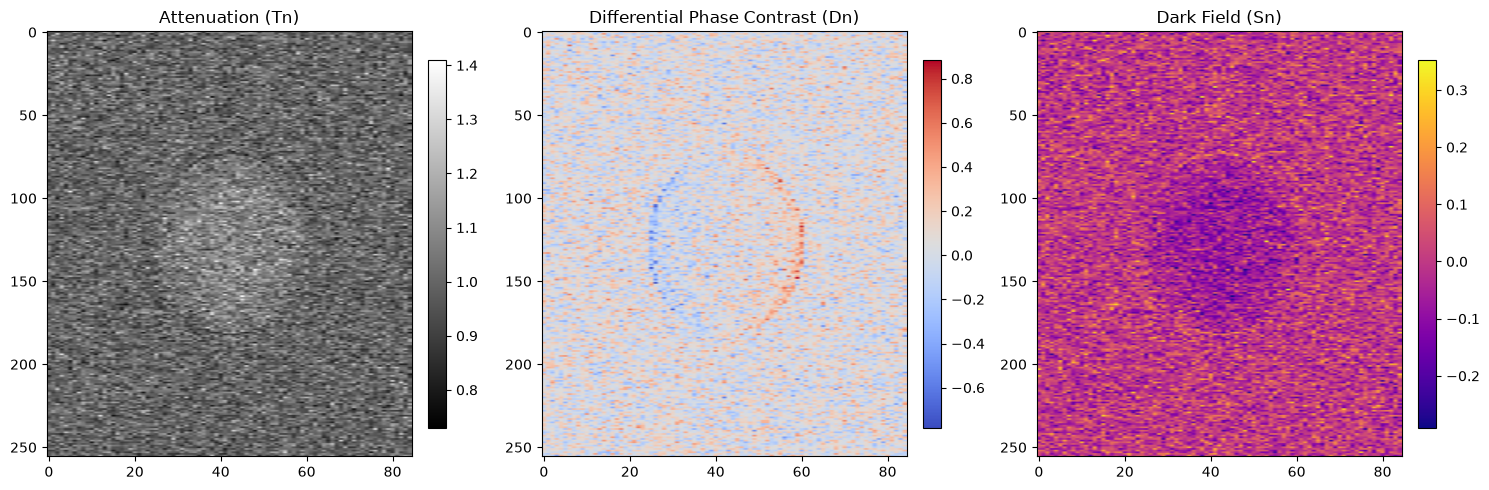

In [18]:
    # 1. Ejecutar cálculo
tn, dn, sn = calcular_imagenes_dfydpc(flat_field_dfydpc, sample_dfydpc)

    # 2. Graficar resultados
graficar_tn_df_sn(tn, dn, sn)

Filtros

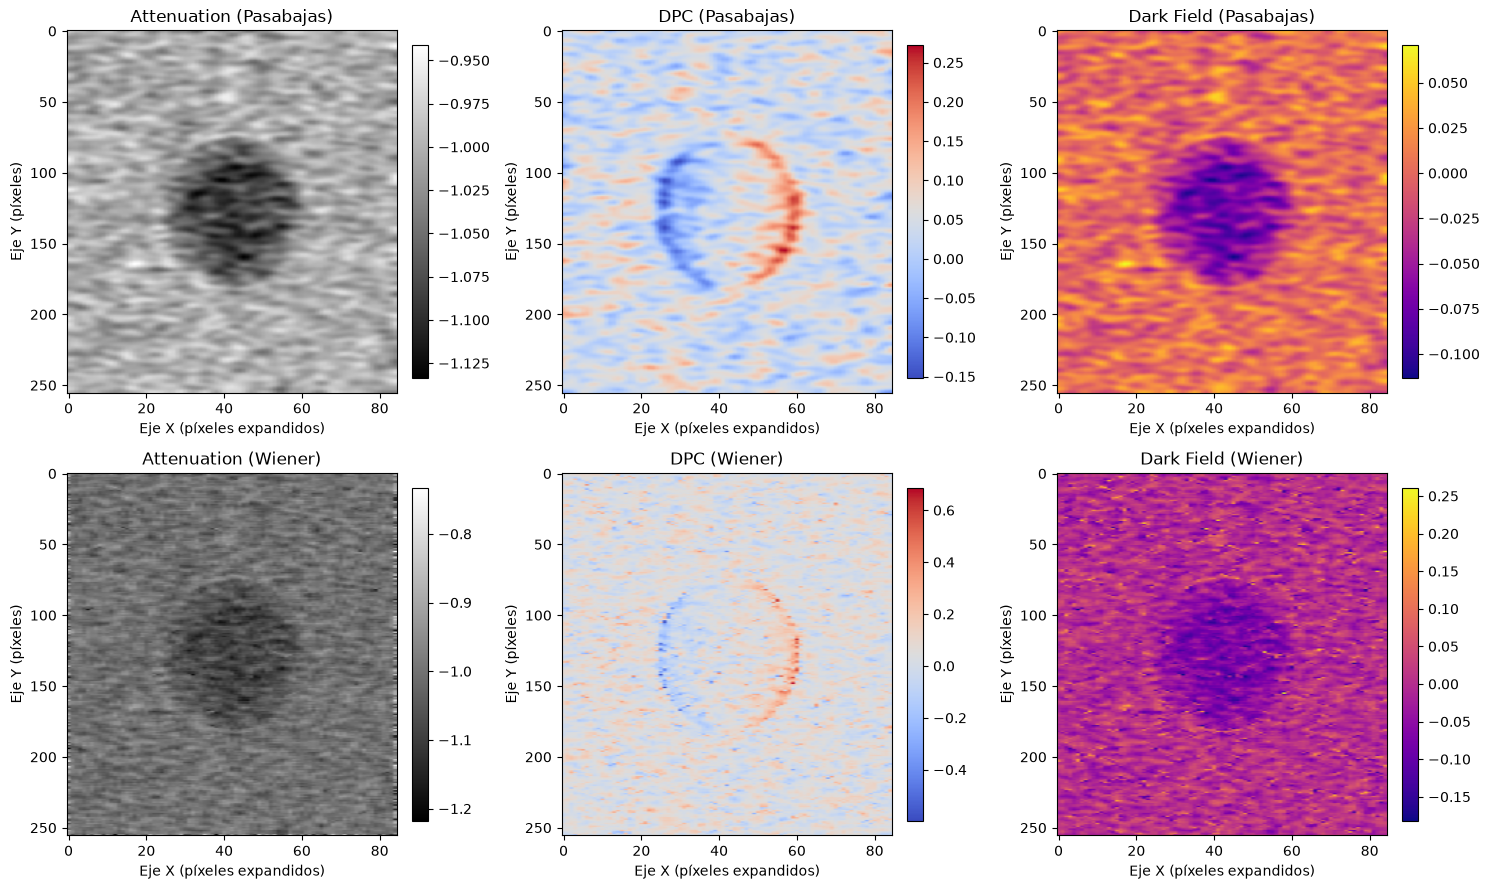

In [19]:

comparar_filtros_2x3(-tn, dn, sn)

---

Resultados

In [20]:
# fig, axes = plt.subplots(1, 4, figsize=(12, 4), constrained_layout=True)

# imagenes = [imagen_attenuacion, phase_grad, phase, dark_field]
# titulos = ["Atenuación", "Diferencial de fase", "Fase", "Dark Field"]

# for ax, img, titulo in zip(axes, imagenes, titulos):
#     ax.imshow(img, cmap="gray")
#     ax.set_title(titulo)
#     ax.axis("off")
#     ax.set_aspect("equal", adjustable="box")

# plt.show()

Adicionales


Ver todos los patrones del barrido

In [21]:
# from pathlib import Path
# import re
# import numpy as np
# import matplotlib.pyplot as plt

# # Definir la ruta base de la carpeta
# directorio_base = Path(r"resultados_barrido step0.2 ap 10")
# flat_fields = {}

# # Buscar automáticamente todos los archivos .raw en la carpeta y subcarpetas
# for archivo_path in directorio_base.glob("**/*.raw"):
#     nombre_archivo = archivo_path.stem  # Ejemplo: "pos_-10"
    
#     # Intentar extraer el número de la posición usando regex (ej. de "pos_-10" extrae -10)

# # Por esto:
#     match = re.search(r'pos_(-?\d+(?:\.\d+)?)', nombre_archivo)
#     key = float(match.group(1)) if match else nombre_archivo
    
#     try:
#         sample = dataCreator(str(archivo_path), pixelsX, pixelsY)
#         flat_fields[key] = sample[0]
#     except (FileNotFoundError, IndexError, ValueError):
#         print(f"Archivo no encontrado o inválido para {nombre_archivo}; se omitirá.")

# # Filtrar únicamente las posiciones que se cargaron exitosamente
# flat_fields_validos = {x: img for x, img in flat_fields.items() if img is not None}

# print("Posiciones válidas cargadas:", list(flat_fields_validos.keys()))

# # Mostrar siempre las primeras 10 filas y 30 columnas
# filas = 30
# columnas = 30
# numero_columnas = 4
# total_validos = len(flat_fields_validos)

# if total_validos > 0:
#     # 1. Extraer todas las regiones de interés primero para calcular un min/max GLOBAL
#     zooms_validos = {}
#     all_values = []
#     for x, ff_image in flat_fields_validos.items():
#         zoom_region = ff_image[:filas, :columnas].astype(np.float64)
#         zooms_validos[x] = zoom_region
#         all_values.extend(zoom_region.flatten())

#     # Calcular límites globales usando percentiles (evita que un píxel quemado arruine el contraste)
#     global_min = np.percentile(all_values, 1)
#     global_max = np.percentile(all_values, 99)

#     numero_filas = int(np.ceil(total_validos / numero_columnas))

#     fig, axes = plt.subplots(
#         numero_filas,
#         numero_columnas,
#         figsize=(20, 4 * numero_filas),
#         squeeze=False,
#         constrained_layout=True,
#     )

#     for ax, (x, zoom_region) in zip(axes.flat, zooms_validos.items()):
#         # Normalización global unificada para todos los subplots
#         if global_max - global_min > 0:
#             zoom_region_norm = np.clip((zoom_region - global_min) / (global_max - global_min), 0, 1)
#         else:
#             zoom_region_norm = np.zeros_like(zoom_region)
            
#         im = ax.imshow(
#             zoom_region_norm,
#             cmap="gray",
#             origin="lower",
#             interpolation="nearest",
#             aspect="auto",
#             vmin=0.0,
#             vmax=1.0
#         )
#         ax.set_title(f"Flat Field - pos_{x} (Global Norm)")
#         fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)

#         ax.set_xlabel("Columnas (0 - 29)")
#         ax.set_ylabel("Filas (0 - 9)")
#         ax.set_xticks(np.arange(columnas))
#         ax.set_yticks(np.arange(filas))
#         ax.grid(True, color="red", linestyle="-", linewidth=0.5, alpha=0.5)

#     # Ocultar los paneles sobrantes de la última fila
#     for ax in axes.flat[total_validos:]:
#         ax.axis("off")

#     plt.show()
# else:
#     print("No se encontraron datos válidos para graficar.")

# # Encontrar automáticamente la posición con el patrón más marcado
# mejor_pos = None
# max_contraste = -1

# for x, ff_image in flat_fields_validos.items():
#     # Promediar verticalmente para obtener el perfil horizontal
#     perfil_horizontal = np.mean(ff_image[:10, :30], axis=0)
    
#     # La desviación estándar mide el contraste neto de las franjas
#     contraste = np.std(perfil_horizontal)
    
#     if contraste > max_contraste:
#         max_contraste = contraste
#         mejor_pos = x

# print(f"La posición óptima con el patrón más marcado es: pos_{mejor_pos}")

In [22]:
# # Iteraciones
# import os
# import shutil
# import subprocess
# metodo='DF_DPC' #DF_DPC O DFyDPC
# # Configuración de los valores del barrido (de -10.0 a 10.0 con pasos de 0.2)
# start, stop, step = -10.0, 10.0, 0.2
# valores = [round(start + i * step, 2) for i in range(int((stop - start) / step) + 1)]

# # Directorios base (ajustados a tu carpeta DF_DPC)
# base_dir = os.path.join(os.getcwd(), metodo)
# build_dir = os.path.join(base_dir, "build")
# results_dir = os.path.join(base_dir, "resultados_barrido")

# # Ruta del archivo de configuración de geometría
# geo_file_path = os.path.join(base_dir, "geometry_config.in")

# # Crear carpeta principal de resultados si no existe
# os.makedirs(results_dir, exist_ok=True)

# for val in valores:
#     print(f"\n==============================================")
#     print(f" Ejecutando simulación para posición: {val}")
#     print(f"==============================================\n")

#     # 1. Leer, actualizar el PRIMER valor y guardar como UNICAMENTE una línea
#     if os.path.exists(geo_file_path):
#         with open(geo_file_path, "r") as f:
#             contenido = f.read().strip()
        
#         partes = contenido.split()
#         if len(partes) >= 3:
#             # Modificamos el PRIMER valor (índice 0) según la iteración
#             partes[0] = f"{float(val):.1f}"
            
#             # Unimos los tres valores en una sola línea
#             linea_unica = f"{partes[0]} {partes[1]} {partes[2]}\n"
            
#             with open(geo_file_path, "w") as f:
#                 f.write(linea_unica)
#         else:
#             print("Advertencia: El archivo no contiene los tres valores esperados.")
#     else:
#         print(f"Advertencia: No se encontró el archivo {geo_file_path}")

#     # 2. Ir a la carpeta build, limpiar y compilar con -j30
#     os.chdir(build_dir)
    
#     # Limpiar contenido de build (equivalente a rm -r *)
#     for item in os.listdir(build_dir):
#         item_path = os.path.join(build_dir, item)
#         if os.path.isfile(item_path) or os.path.islink(item_path):
#             os.unlink(item_path)
#         elif os.path.isdir(item_path):
#             shutil.rmtree(item_path)

#     # Ejecutar CMake y compilación con 30 hilos
#     subprocess.run(["cmake", ".."], check=True)
#     subprocess.run(["make", "-j30"], check=True)

#     # 3. Ejecutar la simulación
#     subprocess.run(["./pepi", "run.mac"], check=True)

#     # 4. Copiar y renombrar los archivos directamente en results_dir (sin subcarpetas)
#     for archivo in os.listdir(build_dir):
#         if archivo.startswith("Frame") or archivo.endswith(".raw"):
#             ruta_origen = os.path.join(build_dir, archivo)
            
#             _, extension = os.path.splitext(archivo)
            
#             # Si el archivo empieza con Frame, puedes mantener parte de su nombre o distinguirlo
#             if archivo.startswith("Frame"):
#                 # Ej: pos_-10.0_Frame_001.raw
#                 nombre_base_archivo = archivo.replace(extension, "")
#                 nuevo_nombre = f"pos_{val}_{nombre_base_archivo}{extension}"
#             else:
#                 # Si es un archivo .raw genérico
#                 nuevo_nombre = f"pos_{val}{extension}"

#             ruta_destino = os.path.join(results_dir, nuevo_nombre)
            
#             shutil.copy(ruta_origen, ruta_destino)

#     print(f"Resultados de la posición {val} guardados en: {results_dir}")
    
#     # Volver al directorio base para la siguiente iteración
#     os.chdir(base_dir)

# print("\n¡Barrido completo finalizado con éxito!")

Generando hasta 1000 esferas sin solapamiento...
¡Archivo CSV guardado como 'esferas_distribuidas.csv' con 1000 esferas!

Abriendo ventana de visualización...


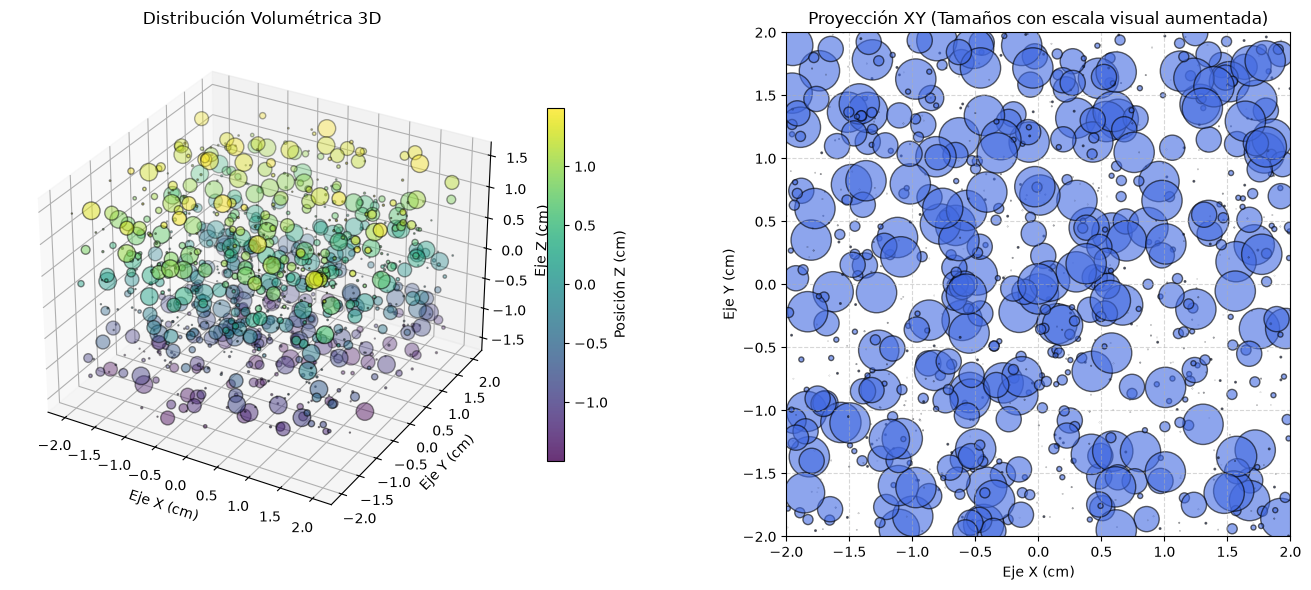

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

def generar_esferas_y_visualizar(nombre_archivo, num_particulas, x_range, y_range, z_range, tipo_tamano, valores_tamano, max_intentos=5000):
    esferas = []
    print(f"Generando hasta {num_particulas} esferas sin solapamiento...")
    
    i = 0
    while i < num_particulas:
        intentos = 0
        colision = True
        
        while colision and intentos < max_intentos:
            intentos += 1
            
            # 1. Determinar el radio
            if tipo_tamano == 'unico':
                r = valores_tamano
            elif tipo_tamano == 'varios':
                if isinstance(valores_tamano, tuple):
                    # Si la tupla tiene solo 2 elementos, se asume rango (min, max) para uniforme
                    if len(valores_tamano) == 2:
                        r = np.random.uniform(valores_tamano[0], valores_tamano[1])
                    else:
                        # Si tiene más de 2 elementos, se escoge aleatoriamente uno de los tamaños fijos
                        r = np.random.choice(valores_tamano)
                elif isinstance(valores_tamano, (list, np.ndarray)):
                    r = np.random.choice(valores_tamano)
            
            # 2. Ajustar límites para evitar desbordes
            x_min_f, x_max_f = x_range[0] + r, x_range[1] - r
            y_min_f, y_max_f = y_range[0] + r, y_range[1] - r
            z_min_f, z_max_f = z_range[0] + r, z_range[1] - r
            
            if x_min_f >= x_max_f or y_min_f >= y_max_f or z_min_f >= z_max_f:
                raise ValueError("La caja es demasiado pequeña para el radio de las esferas.")
            
            # Posición aleatoria
            x = np.random.uniform(x_min_f, x_max_f)
            y = np.random.uniform(y_min_f, y_max_f)
            z = np.random.uniform(z_min_f, z_max_f)
            
            # 3. Comprobar colisiones
            colision = False
            for esp in esferas:
                ex, ey, ez, er = esp
                distancia = np.sqrt((x - ex)**2 + (y - ey)**2 + (z - ez)**2)
                if distancia < (r + er):
                    colision = True
                    break
            
            if not colision:
                esferas.append([x, y, z, r])
                i += 1
                break
                
        if intentos >= max_intentos:
            print(f"\n[Aviso] Se detuvo en {len(esferas)} esferas por saturación del espacio.")
            break

    # Guardar CSV compatible con Geant4
    datos = np.array(esferas)
    np.savetxt(nombre_archivo, datos, delimiter=",", header="x,y,z,r", comments="", fmt="%.6f")
    print(f"¡Archivo CSV guardado como '{nombre_archivo}' con {len(esferas)} esferas!")

    # ==========================================
    # VISUALIZACIÓN: 3D Y PROYECCIÓN XY
    # ==========================================
    fig = plt.figure(figsize=(14, 6))

    # --- Panel 1: Vista 3D ---
    ax1 = fig.add_subplot(1, 2, 1, projection='3d')
    xs = datos[:, 0]
    ys = datos[:, 1]
    zs = datos[:, 2]
    rs = datos[:, 3]

    # Escalamos el tamaño del punto en función del radio real para que se aprecie visualmente
    sc = ax1.scatter(xs, ys, zs, s=rs*20000, c=zs, cmap='viridis', alpha=0.8, edgecolors='k')
    ax1.set_title("Distribución Volumétrica 3D")
    ax1.set_xlabel("Eje X (cm)")
    ax1.set_ylabel("Eje Y (cm)")
    ax1.set_zlabel("Eje Z (cm)")
    fig.colorbar(sc, ax=ax1, label='Posición Z (cm)', shrink=0.7)

    # --- Panel 2: Proyección en el plano XY ---
    ax2 = fig.add_subplot(1, 2, 2)
    
    # Factor de escala visual para que los radios muy pequeños se alcancen a distinguir en el gráfico
    factor_escala_visual = 20.0 

    for x, y, z, r in zip(xs, ys, zs, rs):
        # Multiplicamos 'r' por el factor visual para la gráfica
        circle = plt.Circle((x, y), r * factor_escala_visual, color='royalblue', alpha=0.6, ec='black')
        ax2.add_patch(circle)

    ax2.set_xlim(x_range[0], x_range[1])
    ax2.set_ylim(y_range[0], y_range[1])
    ax2.set_aspect('equal', adjustable='box')
    ax2.set_title("Proyección XY (Tamaños con escala visual aumentada)")
    ax2.set_xlabel("Eje X (cm)")
    ax2.set_ylabel("Eje Y (cm)")
    ax2.grid(True, linestyle='--', alpha=0.5)

    plt.tight_layout()
    print("\nAbriendo ventana de visualización...")
    plt.show()

# ==========================================
# EJECUTAR SCRIPT
# ==========================================
if __name__ == "__main__":
    
    # Límites espaciales basados en tu caja de Wax (ej. 9x9 cm en X-Y, y espesor de 3 cm en Z)
    limites_x = (-2., 2.)  
    limites_y = (-2., 2.)  
    limites_z = (-1.5, 1.5)  
    
    generar_esferas_y_visualizar(
        nombre_archivo="esferas_distribuidas.csv",
        num_particulas=1000,  # Nota: 100,000 esferas saturarían el espacio físico de inmediato; 
                            # se recomienda un número moderado (ej. 30 a 100) para visualización clara.
        x_range=limites_x,
        y_range=limites_y,
        z_range=limites_z,
        tipo_tamano='varios', #varios o unico
        valores_tamano=(0.25e-4, 0.5e-4, 1e-4, 3e-4, 10e-4, 20e-4, 50e-4, 80e-4)  # Tamaños discretos
    )